# code_220 · A release gate needs a working rollback and typed failure path

**Book:** section 41.5. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_41_GUIDE.md), [execution evidence](../CHAPTER_41_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_220).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Deployment contracts bind source-fitted transformations, model state, schema and version. Resource measurements are actual observations of this run, separated from deterministic scientific results; no production service or autonomous engineering clearance is claimed. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or asset is added.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=8020;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
Darwin arm64 CPU; seed 8020


## Freeze a development gate before final shadow assessment
 Fit an old logistic model on600 observations from an earlier generated regime and a candidate on600 independently sampled updated-regime observations. A separate300-row updated development cohort controls a predeclared gate: candidate Brier must beat old by0.005, remain below0.25 overall and below0.30 in each of two observed groups. No final label is inspected while setting that gate. Score500 independent final records in shadow with both models and retain disagreement and group performance whether the candidate passes or fails. Route a declared10-percent hash canary only if the development gate passes; the hash is a stable assignment fixture, not evidence of randomized causal benefit or actual production traffic. This local simulation never grants engineering clearance. Delayed labels and operational monitoring remain separate release responsibilities.


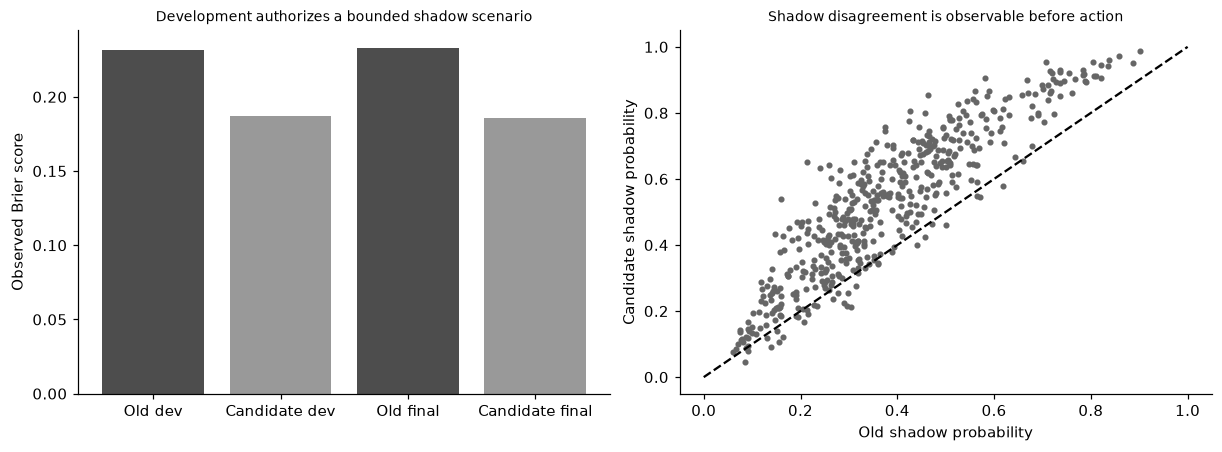

In [2]:
import hashlib
from sklearn.linear_model import LogisticRegression
def sample(n,updated):
    x=rng.normal(size=(n,3));group=x[:,2]>0;logit=(1.2 if updated else .6)*x[:,0]-.7*x[:,1]+(.7 if updated else -.5)*group-.2;y=rng.binomial(1,expit(logit));return x,y,group
xo,yo,go=sample(600,False);xn,yn,gn=sample(600,True);xd,yd,gd=sample(300,True);old=LogisticRegression(C=1).fit(xo,yo);candidate=LogisticRegression(C=1).fit(xn,yn);pd_old=old.predict_proba(xd)[:,1];pd_new=candidate.predict_proba(xd)[:,1];brier=lambda p,y:float(np.mean((p-y)**2));dev_groups=[brier(pd_new[gd==g],yd[gd==g]) for g in [False,True]];gate=bool(brier(pd_new,yd)<=brier(pd_old,yd)-.005 and brier(pd_new,yd)<.25 and max(dev_groups)<.30);xf,yf,gf=sample(500,True);po=old.predict_proba(xf)[:,1];pn=candidate.predict_proba(xf)[:,1];prior_bytes=po.tobytes();old_state={'coef':old.coef_[0].tolist(),'intercept':float(old.intercept_[0]),'version':'old-v1'};assignments=np.array([int(hashlib.sha256(f'request-{i}'.encode()).hexdigest()[:8],16)%100<10 for i in range(500)]);routes=np.where(assignments & gate,'candidate-v2','old-v1');served=np.where(routes=='candidate-v2',pn,po);assert np.allclose(served[routes=='old-v1'],po[routes=='old-v1']);assert not np.any(routes=='candidate-v2') or gate;RESULTS.update(old_source_rows=600,candidate_source_rows=600,development_rows=300,final_shadow_rows=500,development_old_Brier=brier(pd_old,yd),development_candidate_Brier=brier(pd_new,yd),development_candidate_group_Brier=dev_groups,development_gate_passed=gate,final_old_Brier=brier(po,yf),final_candidate_Brier=brier(pn,yf),final_candidate_group_Brier=[brier(pn[gf==g],yf[gf==g]) for g in [False,True]],shadow_decision_disagreement=float(np.mean((po>=.5)!=(pn>=.5))),canary_candidate_requests=int(np.sum(routes=='candidate-v2')),gate_uses_final_labels=False);fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].bar(['Old dev','Candidate dev','Old final','Candidate final'],[brier(pd_old,yd),brier(pd_new,yd),brier(po,yf),brier(pn,yf)],color=['.3','.6','.3','.6']);axes[0].set(ylabel='Observed Brier score',title='Development authorizes a bounded shadow scenario');axes[1].scatter(po,pn,s=9,color='.4');axes[1].plot([0,1],[0,1],color='black',linestyle='--');axes[1].set(xlabel='Old shadow probability',ylabel='Candidate shadow probability',title='Shadow disagreement is observable before action');plt.show()


## Exercise invalid, deferred and rollback paths using retained state
 A valid request has exactly three finite numeric measurements in declared reference units. A wrong unit or missing measurement returns invalid with no probability. A timeout on a valid request may use the retained old package only when that package supports the same event and schema; a simulated solver failure instead returns deferred. Neither missing data nor a failed physical solve is repaired by a guessed safety label. Route a staged25-percent scenario using the same frozen development gate, then inject an operational rollback irrespective of final performance. Restore old-v1 for every valid request and reconstruct predictions directly from retained coefficient/intercept state. Require byte-identical prior probabilities and a matching digest. This is an actual local switch/replay test; incident ownership, live latency budgets and human approvals are not executed by the notebook.


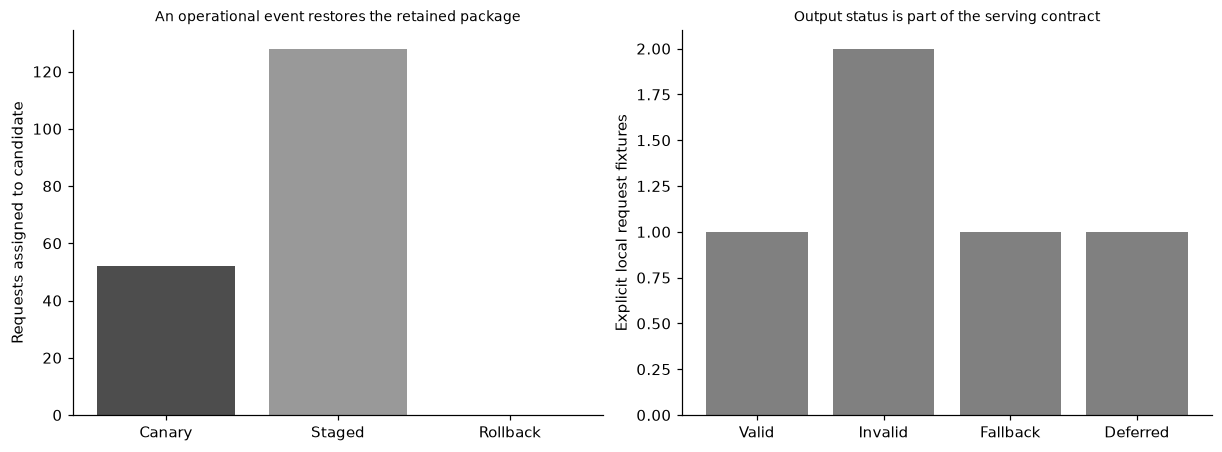

In [3]:
def serve(record,version='candidate-v2',timeout=False,solver_failed=False):
    if set(record)!={'x','unit'} or record['unit']!='reference' or len(record['x'])!=3 or not np.all(np.isfinite(record['x'])):return {'status':'invalid','probability':None,'version':None}
    if solver_failed:return {'status':'deferred','probability':None,'version':None}
    if timeout:version='old-v1'
    x=np.array(record['x'])[None];m=old if version=='old-v1' else candidate;return {'status':'valid_fallback' if timeout else 'valid','probability':float(m.predict_proba(x)[0,1]),'version':version}
valid={'x':xf[0].tolist(),'unit':'reference'};fixtures=[serve(valid),serve({**valid,'unit':'wrong'}),serve({'x':xf[0,:2].tolist(),'unit':'reference'}),serve(valid,timeout=True),serve(valid,solver_failed=True)];assert [r['status'] for r in fixtures]==['valid','invalid','invalid','valid_fallback','deferred'];assert all(r['probability'] is None for r in fixtures if r['status'] in ['invalid','deferred']);assert fixtures[3]['version']=='old-v1';staged=np.array([int(hashlib.sha256(f'request-{i}'.encode()).hexdigest()[:8],16)%100<25 for i in range(500)]) & gate;rollback_routes=np.full(500,'old-v1');replayed=expit(xf@np.array(old_state['coef'])+old_state['intercept']);assert replayed.tobytes()==prior_bytes;assert np.all(rollback_routes=='old-v1');RESULTS.update(failure_fixture_statuses=[r['status'] for r in fixtures],staged_candidate_requests=int(staged.sum()),rollback_old_requests=500,rollback_probability_sha256=hashlib.sha256(replayed.tobytes()).hexdigest(),rollback_prior_probability_bytes_identical=True,invalid_inputs_never_receive_fallback_probability=True,live_service_or_human_approval_executed=False);fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].bar(['Canary','Staged','Rollback'],[int(np.sum(routes=='candidate-v2')),int(staged.sum()),0],color=['.3','.6','.8']);axes[0].set(ylabel='Requests assigned to candidate',title='An operational event restores the retained package');axes[1].bar(['Valid','Invalid','Fallback','Deferred'],[1,2,1,1],color='.5');axes[1].set(ylabel='Explicit local request fixtures',title='Output status is part of the serving contract');plt.show()


In [4]:
summary={'example_id':'code_220','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual old and candidate logistic model fits with independent development gate and final shadow scores', 'deterministic staged routing and explicit valid invalid deferred status contracts', 'actual injected timeout and schema unit failures with bounded fallback rules', 'rollback to retained old parameters and verified identical prior predictions'],'results':RESULTS,'resource_measurements':globals().get('MEASUREMENTS',{}),'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual old and candidate logistic model fits with independent development gate and final shadow scores", "deterministic staged routing and explicit valid invalid deferred status contracts", "actual injected timeout and schema unit failures with bounded fallback rules", "rollback to retained old parameters and verified identical prior predictions"], "elapsed_seconds": 0.308, "example_id": "code_220", "hardware": "Darwin arm64 CPU", "resource_measurements": {}, "results": {"canary_candidate_requests": 52, "candidate_source_rows": 600, "development_candidate_Brier": 0.18697037926928034, "development_candidate_group_Brier": [0.18442978072763724, 0.18968619150345054], "development_gate_passed": true, "development_old_Brier": 0.23184783286356578, "development_rows": 300, "failure_fixture_statuses": ["valid", "invalid", "invalid", "valid_fallback", "deferred"], "final_candidate_Brier": 0.18592402789735085, "final_candidate_group_Brier": [0.18